<table align="center">
  <td align="center"><a target="_blank" href="http://introtodeeplearning.com">
        <img src="https://i.ibb.co/Jr88sn2/mit.png" style="padding-bottom:5px;" />
      Visit MIT Deep Learning</a></td>
  <td align="center"><a target="_blank" href="https://colab.research.google.com/github/MITDeepLearning/introtodeeplearning/blob/master/lab1/TF_Part2_Music_Generation.ipynb">
        <img src="https://i.ibb.co/2P3SLwK/colab.png"  style="padding-bottom:5px;" />Run in Google Colab</a></td>
  <td align="center"><a target="_blank" href="https://github.com/MITDeepLearning/introtodeeplearning/blob/master/lab1/TF_Part2_Music_Generation.ipynb">
        <img src="https://i.ibb.co/xfJbPmL/github.png"  height="70px" style="padding-bottom:5px;"  />View Source on GitHub</a></td>
</table>

# Copyright Information

In [1]:
# Copyright 2026 MIT Introduction to Deep Learning. All Rights Reserved.
#
# Licensed under the MIT License. You may not use this file except in compliance
# with the License. Use and/or modification of this code outside of MIT Introduction
# to Deep Learning must reference:
#
# © MIT Introduction to Deep Learning
# http://introtodeeplearning.com
#

In [6]:
# Import Tensorflow 2.0
import tensorflow as tf

# Download and import the MIT Introduction to Deep Learning package
!pip install mitdeeplearning --quiet
import mitdeeplearning as mdl

# Import all remaining packages
import numpy as np
import os
import time
import functools
from IPython import display as ipythondisplay
from tqdm import tqdm
from scipy.io.wavfile import write

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## Train text

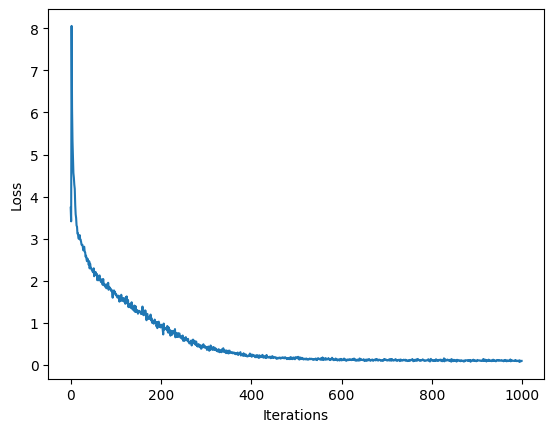

100%|██████████| 1000/1000 [38:27<00:00,  2.31s/it]


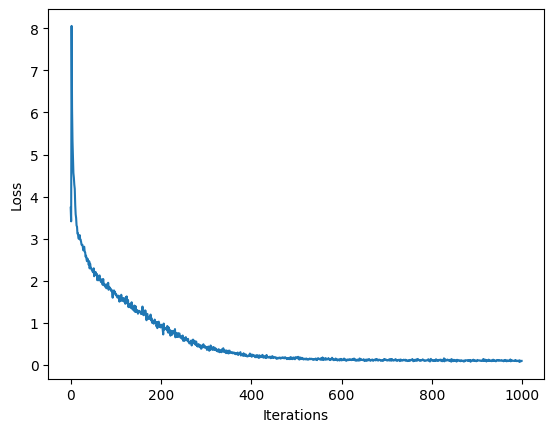

In [18]:

def get_batch(vectorized_songs, seq_length, batch_size):
   # the length of the vectorized songs string
   n = vectorized_songs.shape[0] - 1
   # randomly choose the starting indices for the examples in the training batch
   idx = np.random.choice(n-seq_length, batch_size)

   input_batch = []
   output_batch = []

   for start in idx:
      input_sequence = vectorized_songs[start : start + seq_length]
      target_sequence = vectorized_songs[start + 1 : start + seq_length + 1]

      input_batch.append(input_sequence)
      output_batch.append(target_sequence)

   # x_batch, y_batch provide the true inputs and targets for network training
   x_batch = np.reshape(input_batch, [batch_size, seq_length])
   y_batch = np.reshape(output_batch, [batch_size, seq_length])
   return x_batch, y_batch

def LSTM(rnn_units):
  return tf.keras.layers.LSTM(
    rnn_units,
    return_sequences=True,
    recurrent_initializer='glorot_uniform',
    recurrent_activation='sigmoid',
    stateful=False,
  )

### Defining the RNN Model ###

def build_model(vocab_size, embedding_dim, rnn_units, batch_size):
  model = tf.keras.Sequential([
    # Layer 1: Embedding layer to transform indices into dense vectors
    #   of a fixed embedding size
    tf.keras.layers.Embedding(vocab_size, embedding_dim),

    # Layer 2: LSTM with `rnn_units` number of units.
    LSTM(rnn_units),

    # Layer 3: Dense (fully-connected) layer that transforms the LSTM output
    #   into the vocabulary size.
    tf.keras.layers.Dense(vocab_size)
  ])

  return model

def compute_loss(labels, logits):
  loss = tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
  return loss

@tf.function
def train_step(x, y):
  # Use tf.GradientTape()
  with tf.GradientTape() as tape:

    y_hat = model_text(x)

    loss = compute_loss(y, y_hat)

  # Now, compute the gradients
  grads = tape.gradient(loss, model_text.trainable_variables)

  # Apply the gradients to the optimizer so it can update the model accordingly
  optimizer.apply_gradients(zip(grads, model_text.trainable_variables))
  return loss

# main start
training_story = """Ala has a cat, and the cat has a name.
Ola has a dog, and the dog likes to run.
Ela has a fish that swims in a little bowl.
Every pet loves its kind and caring owner.
The cat drinks water, the dog eats, and the fish swims.
Ala, Ola, and Ela walk together in the park.
Tall green trees grow there, and little birds sing.
In the morning, Ala wakes up and makes breakfast.
Ola pours milk into a cup, and Ela opens the window.
The cat jumps onto a chair and looks at the table.
The dog wags its tail and waits by the door.
After breakfast, the children pack their books.
Then they walk to school through the green park.
After class, they meet beneath an old oak tree.
Together they kick a ball and laugh out loud.
When it rains, they build a small house with blocks.
In the evening, they read a story and feed their pets.
Ala helps Ola water the flowers in the garden.
Ela draws a little house while the cat sleeps beside her.
The dog runs across the grass and chases a small ball.
On Saturday, the whole family travels to the woods.
The children collect pinecones and listen to forest birds.
When they come home, they make tea and eat cake.
At the end of the day, everyone says good night.
On Monday, Ala walks to school with Ola.
Ela carries a colorful notebook and two pencils.
In the first lesson, the children read a short story.
The teacher asks them to write a few sentences.
Ala writes about her cat, which likes to drink milk.
Ola writes about her dog, which watches the house.
Ela draws a fish that swims around its bowl.
After class, all three friends go to the playground.
On the field, the children kick the ball toward the goal.
Ala passes the ball to Ola, and Ola passes it to Ela.
The dog runs after the ball, then returns to its owner.
The cat watches the children from behind the fence.
After playing, the children walk calmly back home.
On Tuesday morning, rain falls over the little town.
Ala takes an umbrella and puts on a yellow coat.
Ola wears her boots, and Ela takes a blue umbrella.
Together they walk to school along the wet sidewalk.
Small puddles shine beside the road to the park.
The children walk carefully and step around each puddle.
In class, they hang their coats up to dry.
During the break, they read a book about the forest.
In the afternoon, the rain stops falling.
A bright rainbow appears in the sky.
Ola points it out to her younger brother.
On Wednesday, the children visit the library.
The librarian chooses some new books for them.
Ala chooses a story about a long journey.
Ola borrows a book about animals.
Ela finds an atlas of plants and flowers.
The children read quietly together at a table.
The cat lies down on the rug and falls asleep.
The dog rests by the door and listens to them talk.
On Thursday, the children help in the garden.
Ala rakes the leaves, and Ola waters the garden beds.
Ela plants small seeds beside the fence.
Each seed needs soil, water, and sunlight to grow.
After a few days, a green leaf comes out of the soil.
The children check their plants every day.
A butterfly lands on a red flower.
A bee flies over the garden in search of nectar.
Ala looks at the garden and smiles happily.
On Friday after school, the children bake cookies.
Ola stirs the flour, and Ala adds some milk.
Ela places the cookie dough on a baking tray.
An adult puts the tray into the warm oven.
Soon the whole house smells sweet like vanilla.
The cookies cool on the table beside the plates.
Everyone gets one cookie and a glass of milk.
The cat waits by the table and gets its own bowl.
The dog drinks water and rests on its soft bed.
On Saturday, the family tidies up the house.
Ala puts the books neatly on the shelf.
Ola sweeps the floor in her room.
Ela folds her clothes and puts them in the closet.
Mother prepares lunch in the kitchen.
Father fixes the loose handle on the front door.
After work, everyone eats lunch at the table.
Then they rest and tell each other stories.
On Sunday morning, the family takes a bus to the woods.
The children pack sandwiches, apples, and a bottle of water.
They spread a blanket on a sunny forest clearing.
Ala sees a squirrel high up in a tree.
Ola finds a colorful feather beside the path.
Ela hears birds singing in the green treetops.
The family walks slowly and looks at the forest flowers.
No one breaks branches or leaves any litter behind.
After the walk, the children eat apples and drink water.
In the evening, they return home tired but happy.
On Monday, another school week begins.
Ala remembers her notebook and packs it in her bag.
Ola checks the class schedule beside the door.
Ela takes a book, a pencil, and an eraser.
The children greet their friends outside the school.
Together they read, write, and learn new things.
After class, they walk home along the same road.
At home, their cat, dog, and fish are waiting.
Every pet has its own place and its own bowl.
Ala pours clean water into the fish bowl.
Ola feeds the cat, and Ela takes the dog outside.
Then the children do their homework at the big table.
When they do not know an answer, they ask for help.
After studying, they play a board game together.
The winner shares a tasty dessert with everyone.
Sometimes Ala wins, and sometimes Ola or Ela wins.
The most important thing is that they play together.
Every evening, the children choose clothes for the morning.
Before bed, they wash their hands and read a short story.
The cat curls up on a soft and cozy blanket.
The dog falls asleep quietly beside its bed.
The fish swims slowly beneath a green plant.
The house becomes quiet, warm, and peaceful.
Ala, Ola, and Ela wish everyone a good night."""
text = (training_story + "\n") * 5

vocabtext = sorted(set(text))
char_to_id = {char: i for i, char in enumerate(vocabtext)}
vectorized_text = np.array([char_to_id[c] for c in text], dtype=np.int32)

breakpoint()

print("There are", len(vectorized_text), "characters in the test dataset ")
print("There are", len(vocabtext), "unique characters in the test dataset ")
breakpoint()

x_batch_text, y_batch_text = get_batch(vectorized_text, seq_length=5, batch_size=1)
breakpoint()

modeltext = build_model(len(vocabtext), embedding_dim=256, rnn_units=1024, batch_size=32)
modeltext.build(tf.TensorShape([32, 100])) 
modeltext.summary()

x_text, y_text = get_batch(vectorized_text, seq_length=100, batch_size=32)
pred_text = modeltext(x_text)
print("Input shape:      ", x_text.shape, " # (batch_size, sequence_length)")
print("Prediction shape: ", pred_text.shape, "# (batch_size, sequence_length, vocab_size)")
breakpoint()

example_batch_loss_text = compute_loss(y_text, pred_text)

print("Prediction shape: ", pred_text.shape, " # (batch_size, sequence_length, vocab_size)")
print("scalar_loss:      ", example_batch_loss_text.numpy().mean())

vocab_size_text = len(vocabtext)

# Model parameters:
params = dict(
  num_training_iterations = 1000,  # Increase if the generated text is still random
  batch_size = 8,  # Experiment between 1 and 64
  seq_length = 100,  # Experiment between 50 and 500
  learning_rate = 5e-3,  # Experiment between 1e-5 and 1e-1
  embedding_dim = 256,
  rnn_units = 1024,  # Experiment between 1 and 2048
)

# Checkpoint location:
checkpoint_dir_text = './training_checkpoints_text'
checkpoint_prefix_text = os.path.join(checkpoint_dir_text, "my_ckpt.weights.h5")
os.makedirs(checkpoint_dir_text, exist_ok=True)


### Define optimizer and training operation ###

model_text = build_model(vocab_size_text, params["embedding_dim"], params["rnn_units"], params["batch_size"])

optimizer = tf.keras.optimizers.Adam(params["learning_rate"])


##################
# Begin training!#
##################

history = []
plotter = mdl.util.PeriodicPlotter(sec=2, xlabel='Iterations', ylabel='Loss')

if hasattr(tqdm, '_instances'): tqdm._instances.clear() # clear if it exists
for iter in tqdm(range(params["num_training_iterations"])):

  # Grab a batch and propagate it through the network
  x_batch_text, y_batch_text = get_batch(vectorized_text, params["seq_length"], params["batch_size"])
  loss = train_step(x_batch_text, y_batch_text)

  history.append(loss.numpy().mean())
  plotter.plot(history)

  # Update the model with the changed weights!
  if iter % 100 == 0:
    model_text.save_weights(checkpoint_prefix_text)

# Save the trained model and the weights
model_text.save_weights(checkpoint_prefix_text)

## Testing model

In [20]:
def generate_text(model, start_string, generation_length=10):
    input_ids = [char_to_id[c] for c in start_string]
    id_to_char = {idx: char for char, idx in char_to_id.items()}
    text_generated = []

    for _ in range(generation_length):
        context = input_ids[-params["seq_length"]:]
        input_eval = tf.constant([context], dtype=tf.int32)
        predictions = model(input_eval)
        next_logits = predictions[0, -1, :]
        predicted_id = tf.random.categorical(
            next_logits[tf.newaxis, :], num_samples=1
        )[0, 0].numpy()

        input_ids.append(int(predicted_id))
        text_generated.append(id_to_char[int(predicted_id)])

    return start_string + "".join(text_generated)


start_string = "cat"
generated_text = generate_text(
    model_text, start_string=start_string, generation_length=500
)
print(generated_text)

cat, dog, and the dog likes to run.
Ela has a fish that swims in a little bowl.
After class, and a gets one a soft and cozy blanket.
The dog falls asleep quietly beside its bed.
The fish swims slowly beneath a green plant.
The house becomes quiet, warm, and peaceful.
Ala, Ola, and Ela walk together in the park.
Tall green trees grow there, and little birds sing.
In the morning, Ala wakes up and makes breakfast.
Ola pours milk into a cup, and Ala ads beside its bed.
The fish swims slowly beneath a g
